#Pre_Entrega - Número 2 - Grupo 11
Integrantes: Biaiñ Joaquin, Facenda Selena y Ferreyra Iara

#1. Tema y Definición del Objetivo
**Tema:** Predicción y clasificación litofacial basada en registros de pozos (petrofísica y geofísica de reservorios).

**Objetivo del proyecto**:  Analizar las propiedades físicas de las rocas (como rayos gamma, resistividad y porosidad) medidas en diferentes pozos, explorar sus relaciones estadísticas y preparar/transformar los datos para utilizarlos en modelos de aprendizaje automático capaces de clasificar facies litológicas de manera automática.

#2. Exploración de Datos con Pandas


In [ ]:
import pandas as pd

# Cargar el dataset
df = pd.read_csv("facies_data.csv")

# 1. Tamaño y dimensiones
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")

# 2. Tipos de datos y nulos
display(df.info())

# 3. Estadísticas descriptivas básicas
display(df.describe())

Dimensiones del dataset: 3232 filas y 11 columnas.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3232 entries, 0 to 3231
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Facies     3232 non-null   int64  
 1   Formation  3232 non-null   object 
 2   Well Name  3232 non-null   object 
 3   Depth      3232 non-null   float64
 4   GR         3232 non-null   float64
 5   ILD_log10  3232 non-null   float64
 6   DeltaPHI   3232 non-null   float64
 7   PHIND      3232 non-null   float64
 8   PE         3232 non-null   float64
 9   NM_M       3232 non-null   int64  
 10  RELPOS     3232 non-null   float64
dtypes: float64(7), int64(2), object(2)
memory usage: 277.9+ KB


None

,Facies,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
count,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000
mean,4.422030,2875.824567,66.135769,0.642719,3.559642,13.483213,3.725014,1.498453,0.520287
std,2.504243,131.006274,30.854826,0.241845,5.228948,7.698980,0.896152,0.500075,0.286792
min,1.000000,2573.500000,13.250000,-0.025949,-21.832000,0.550000,0.200000,1.000000,0.010000
25%,2.000000,2791.000000,46.918750,0.492750,1.163750,8.346750,3.100000,1.000000,0.273000
50%,4.000000,2893.500000,65.721500,0.624437,3.500000,12.150000,3.551500,1.000000,0.526000
75%,6.000000,2980.000000,79.626250,0.812735,6.432500,16.453750,4.300000,2.000000,0.767250
max,9.000000,3122.500000,361.150000,1.480000,18.600000,84.400000,8.094000,2.000000,1.000000


### Interpretación de Estadísticas Descriptivas (`df.describe()`)

* **`count` (Conteo):** Cantidad de registros no nulos presentes en esa columna. Todas marcan `3232.0`, lo que confirma que no quedaron celdas vacías en esta selección.
* **`mean` (Media / Promedio):** La suma de todos los valores dividida por el total de filas. Indica el valor central o promedio de cada medición.
* **`std` (Desviación Estándar):** Mide la dispersión de los datos respecto a la media. Valores altos indican mayor variabilidad o presencia de colas largas.
* **`min` (Mínimo):** El valor más bajo registrado en la columna.
* **`25%` (Primer Cuartil / $Q_1$):** El 25% de las observaciones se encuentra por debajo de este valor.
* **`50%` (Mediana / Segundo Cuartil):** El centro exacto de la distribución; el 50% de los datos es menor y el 50% es mayor. Si difiere mucho de la media, denota asimetría o presencia de valores atípicos (*outliers*).
* **`75%` (Tercer Cuartil / $Q_3$):** El 75% de las observaciones cae por debajo de este valor.
* **`max` (Máximo):** El valor más alto registrado en la columna.

### Descripción de las Columnas y Variables del Dataset

* **`Facies` (Variable Target / Categórica discreta):** Código numérico (de 1 a 9) que representa la facies sedimentaria o litológica identificada a partir de núcleos/testigos de roca (*cores*):
  * `1`: Arenisca no marina (*Nonmarine sandstone*)
  * `2`: Limolita gruesa no marina (*Nonmarine coarse siltstone*)
  * `3`: Limolita fina no marina (*Nonmarine fine siltstone*)
  * `4`: Limolita y lutita marina (*Marine siltstone and shale*)
  * `5`: Lodolita / mudstone calcáreo (*Mudstone*)
  * `6`: Wackestone
  * `7`: Dolomía (*Dolomite*)
  * `8`: Packstone
  * `9`: Bafflestone / Boundstone

* **`Depth` (Profundidad):** Profundidad medida a lo largo del pozo (*Measured Depth*), expresada en pies (ft), muestreada a intervalos regulares de 0,5 ft.

* **`GR` (Gamma Ray / Rayos Gamma):** Medición de radiactividad natural de la formación rocosa expresada en unidades API. Es clave para discriminar litologías arcillosas/lutitas (valores altos de GR) de rocas reservorio como areniscas o carbonatos limpios (valores bajos de GR).

* **`ILD_log10` (Resistividad Profunda en Escala Logarítmica):** Logaritmo en base 10 de la resistividad eléctrica profunda ($\log_{10}(\text{Resistividad en } \Omega\cdot\text{m})$). Permite evaluar fluidos en la formación (agua de formación vs. hidrocarburos) y contrastes de permeabilidad/litología.

* **`DeltaPHI` (Diferencia Neutrón - Densidad):** Diferencia calculada entre la porosidad neutrón y la porosidad de densidad. Es útil para identificar efectos de matriz mineralógica pesada, presencia de arcillas o efecto de gas (cruce neutrón-densidad).

* **`PHIND` (Porosidad Promedio Neutrón-Densidad):** Porosidad total aparente calculada mediante el promedio entre la porosidad neutrón y la de densidad. Expresa la capacidad de almacenamiento de fluidos de la roca en porcentaje (%).

* **`PE` (Photoelectric Effect / Efecto Fotoeléctrico):** Medición de la absorción fotoeléctrica de la formación rocosa expresada en barns/electrón (b/e). Es altamente sensible al número atómico medio de la roca, por lo que permite determinar directamente la litología de la matriz (ej. areniscas ~1,8; dolomías ~3,14; calizas ~5,08).

* **`NM_M` (Ambiente No Marino / Marino):** Indicador geológico binario del ambiente depositacional:
  * `1`: Ambiente no marino (*Non-marine*)
  * `2`: Ambiente marino (*Marine*)

* **`RELPOS` (Posición Relativa):** Posición relativa normalizada (de 0 a 1) del estrato dentro del ciclo o secuencia estratigráfica deposicional, aportando contexto geológico vertical al modelo.

#3. Transformación y Limpieza de Datos con Pandas


In [ ]:
# Ver los pozos únicos incluidos en el dataset
print("Pozos disponibles:", df['Well Name'].unique())

# Conteo de registros por cada Facies (para ver si hay desbalance de clases)
print("\nDistribución de Facies:\n", df['Facies'].value_counts())

# Ejemplo de transformación: Filtrar datos de un pozo en particular para un análisis enfocado
# pozo_ejemplo = df[df['Well Name'] == df['Well Name'].unique()[0]]

Pozos disponibles: ['SHRIMPLIN' 'SHANKLE' 'LUKE G U' 'CROSS H CATTLE' 'NOLAN' 'Recruit F9'
 'NEWBY' 'CHURCHMAN BIBLE']

Distribución de Facies:
 Facies
2    738
3    615
8    498
6    462
1    259
5    217
4    184
9    161
7     98
Name: count, dtype: int64


#4. Visualización de Datos con Pandas y Matplotlib
Para cumplir con la parte de visualización, realizamos un histograma de los rayos gamma (GR) y un gráfico de dispersión cruzada (cross-plot)

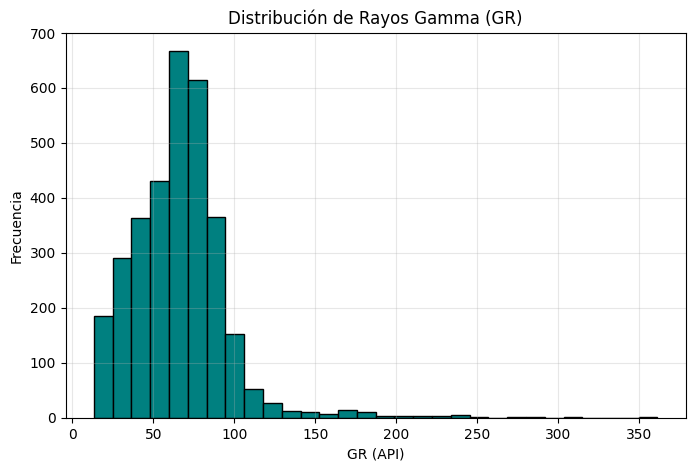

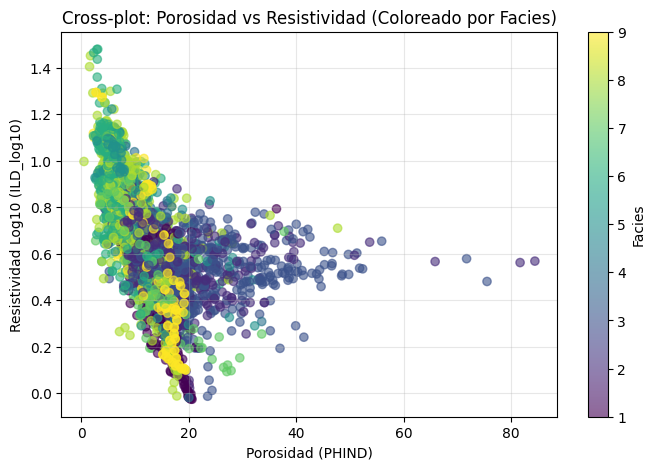

In [ ]:
import matplotlib.pyplot as plt

# Configurar estilo básico
plt.figure(figsize=(8, 5))

# Histograma de la curva de Rayos Gamma (GR)
df['GR'].plot(kind='hist', bins=30, color='teal', edgecolor='black')
plt.title('Distribución de Rayos Gamma (GR)')
plt.xlabel('GR (API)')
plt.ylabel('Frecuencia')
plt.grid(True, alpha=0.3)
plt.show()

# Gráfico de dispersión (Cross-plot) entre Porosidad y Resistividad
plt.figure(figsize=(8, 5))
plt.scatter(df['PHIND'], df['ILD_log10'], c=df['Facies'], cmap='viridis', alpha=0.6)
plt.title('Cross-plot: Porosidad vs Resistividad (Coloreado por Facies)')
plt.xlabel('Porosidad (PHIND)')
plt.ylabel('Resistividad Log10 (ILD_log10)')
plt.colorbar(label='Facies')
plt.grid(True, alpha=0.3)
plt.show()